In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

GPU available: True
GPU: Tesla T4


In [ ]:
#KGAT_cc3bd37951dd4ebc867111a47205f1a8

In [ ]:
import os
from getpass import getpass

os.environ["KAGGLE_API_TOKEN"] = getpass(
    "Enter your new Kaggle API token: "
)

print("Kaggle token configured for this session.")

Enter your new Kaggle API token: ··········
Kaggle token configured for this session.


In [ ]:
import os
import subprocess
from pathlib import Path

data_dir = Path("/content/deepfake_dataset")
data_dir.mkdir(parents=True, exist_ok=True)

result = subprocess.run(
    [
        "kaggle", "datasets", "download",
        "-d", "manjilkarki/deepfake-and-real-images",
        "-p", str(data_dir)
    ],
    env=os.environ.copy(),
    text=True,
    capture_output=True
)

print(result.stdout)

if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset download failed.")

print("Download complete.")
print("Files:", [p.name for p in data_dir.iterdir()])

Dataset URL: https://www.kaggle.com/datasets/manjilkarki/deepfake-and-real-images
License(s): unknown


Download complete.
Files: ['deepfake-and-real-images.zip']


In [ ]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/deepfake_dataset/deepfake-and-real-images.zip"
)
extract_dir = Path("/content/deepfake_dataset/extracted")
extract_dir.mkdir(parents=True, exist_ok=True)

if not zip_path.exists():
    raise FileNotFoundError(
        "Dataset ZIP not found. Complete Step 2 first."
    )

with zipfile.ZipFile(zip_path, "r") as z:
    print("Files in ZIP:", len(z.namelist()))
    z.extractall(extract_dir)

print("\nExtraction complete.")
print("Folders:", [p.name for p in extract_dir.iterdir()])

Files in ZIP: 190335

Extraction complete.
Folders: ['Dataset']


In [ ]:
from pathlib import Path

data_dir = Path("/content/deepfake_dataset/extracted/Dataset")

for split in ["Train", "Validation", "Test"]:
    print(f"\n{split}")

    for label in ["Fake", "Real"]:
        folder = data_dir / split / label

        if not folder.exists():
            print(f"  {label}: folder missing")
            continue

        count = sum(
            1 for p in folder.rglob("*")
            if p.is_file() and p.suffix.lower() in
            [".jpg", ".jpeg", ".png", ".webp", ".bmp"]
        )

        print(f"  {label}: {count:,} images")


Train
  Fake: 70,001 images
  Real: 70,001 images

Validation
  Fake: 19,641 images
  Real: 19,787 images

Test
  Fake: 5,492 images
  Real: 5,413 images


### **Restnet50 model**

In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_dir = Path("/content/deepfake_dataset/extracted/Dataset")

# ResNet50 preprocessing
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_data = datasets.ImageFolder(
    data_dir / "Train", transform=train_transform
)
val_data = datasets.ImageFolder(
    data_dir / "Validation", transform=test_transform
)
test_data = datasets.ImageFolder(
    data_dir / "Test", transform=test_transform
)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True,
    num_workers=0, pin_memory=True
)
val_loader = DataLoader(
    val_data, batch_size=32, shuffle=False,
    num_workers=0, pin_memory=True
)
test_loader = DataLoader(
    test_data, batch_size=32, shuffle=False,
    num_workers=0, pin_memory=True
)

print("Device:", device)
print("Class mapping:", train_data.class_to_idx)
print("Training images:", len(train_data))
print("Validation images:", len(val_data))
print("Test images:", len(test_data))
print("Training batches:", len(train_loader))

Device: cuda
Class mapping: {'Fake': 0, 'Real': 1}
Training images: 140002
Validation images: 39428
Test images: 10905
Training batches: 4376


In [ ]:
import torch
import torch.nn as nn
from torchvision.models import resnet50, ResNet50_Weights

# Load ResNet50 with pretrained ImageNet weights
model = resnet50(weights=ResNet50_Weights.DEFAULT)

# Freeze the pretrained layers
for param in model.parameters():
    param.requires_grad = False

# Replace the final layer for Fake and Real classification
model.fc = nn.Linear(model.fc.in_features, 2)

model = model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.fc.parameters(), lr=0.001)

print("Model: ResNet50")
print("Device:", device)
print("Output classes:", model.fc.out_features)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Class mapping:", train_data.class_to_idx)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 124MB/s]


Model: ResNet50
Device: cuda
Output classes: 2
Trainable parameters: 4098
Class mapping: {'Fake': 0, 'Real': 1}


In [ ]:
from tqdm.auto import tqdm
import torch

num_epochs = 3

train_losses = []
val_losses = []
val_accuracies = []

for epoch in range(num_epochs):

    # Training
    model.train()
    running_loss = 0.0

    for images, labels in tqdm(train_loader, desc=f"Epoch {epoch + 1} Training"):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    # Validation
    model.eval()
    val_running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f"Epoch {epoch + 1} Validation"):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = val_running_loss / len(val_loader.dataset)
    val_accuracy = correct / total

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f"\nEpoch [{epoch + 1}/{num_epochs}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Epoch 1 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

Epoch 1 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


Epoch [1/3]
Train Loss: 0.3420
Validation Loss: 0.3952
Validation Accuracy: 82.30%


Epoch 2 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

Epoch 2 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


Epoch [2/3]
Train Loss: 0.3406
Validation Loss: 0.3760
Validation Accuracy: 83.35%


Epoch 3 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

Epoch 3 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


Epoch [3/3]
Train Loss: 0.3392
Validation Loss: 0.3641
Validation Accuracy: 84.03%


In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate test accuracy
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"ResNet50 Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=["Fake", "Real"],
        digits=4
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

ResNet50 Test Accuracy: 72.31%

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6848    0.8341    0.7521      5492
        Real     0.7839    0.6104    0.6863      5413

    accuracy                         0.7231     10905
   macro avg     0.7343    0.7223    0.7192     10905
weighted avg     0.7340    0.7231    0.7195     10905


Confusion Matrix:
[[4581  911]
 [2109 3304]]


In [ ]:
import json
import torch
from pathlib import Path

# Create a folder for ResNet50 results
results_dir = Path("/content/resnet50_results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save model weights
torch.save(
    model.state_dict(),
    results_dir / "resnet50_best.pth"
)

# Save test accuracy and classification metrics
from sklearn.metrics import classification_report, confusion_matrix

report = classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"],
    output_dict=True,
    zero_division=0
)

results = {
    "model": "ResNet50",
    "test_accuracy": float(test_accuracy),
    "classification_report": report,
    "confusion_matrix": confusion_matrix(
        all_labels, all_predictions
    ).tolist()
}

with open(results_dir / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

print("Model and test metrics saved successfully.")
print("Test accuracy:", f"{test_accuracy * 100:.2f}%")
print("Saved location:", results_dir)

Model and test metrics saved successfully.
Test accuracy: 72.31%
Saved location: /content/resnet50_results


In [ ]:
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/resnet50_results",
    "zip",
    "/content/resnet50_results"
)

files.download(zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import torch
import torch.nn as nn

# Unfreeze the last ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Keep earlier layers frozen; train layer4 and the final classifier
optimizer = torch.optim.Adam(
    [
        {"params": model.layer4.parameters(), "lr": 0.00001},
        {"params": model.fc.parameters(), "lr": 0.0001}
    ]
)

criterion = nn.CrossEntropyLoss()

print("Fine-tuning setup complete.")
print("Trainable blocks: layer4 and fc")
print("Learning rate for layer4: 0.00001")
print("Learning rate for fc: 0.0001")

Fine-tuning setup complete.
Trainable blocks: layer4 and fc
Learning rate for layer4: 0.00001
Learning rate for fc: 0.0001


In [ ]:
from tqdm.auto import tqdm
import torch

num_finetune_epochs = 2

for epoch in range(num_finetune_epochs):

    # Training
    model.train()
    train_running_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc=f"Fine-tuning Epoch {epoch + 1}"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_running_loss += loss.item() * images.size(0)

    train_loss = train_running_loss / len(train_loader.dataset)

    # Validation
    model.eval()
    val_running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"Validation Epoch {epoch + 1}"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = val_running_loss / len(val_loader.dataset)
    val_accuracy = correct / total

    print(f"\nFine-tuning Epoch [{epoch + 1}/{num_finetune_epochs}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

Fine-tuning Epoch 1:   0%|          | 0/4376 [00:00<?, ?it/s]

Validation Epoch 1:   0%|          | 0/1233 [00:00<?, ?it/s]


Fine-tuning Epoch [1/2]
Train Loss: 0.1626
Validation Loss: 0.1730
Validation Accuracy: 93.12%


Fine-tuning Epoch 2:   0%|          | 0/4376 [00:00<?, ?it/s]

Validation Epoch 2:   0%|          | 0/1233 [00:00<?, ?it/s]


Fine-tuning Epoch [2/2]
Train Loss: 0.0789
Validation Loss: 0.1537
Validation Accuracy: 94.04%


In [ ]:
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Fine-tuned ResNet50 Test Accuracy: {test_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(all_labels, all_predictions))

Fine-tuned ResNet50 Test Accuracy: 83.32%

Classification Report:
              precision    recall  f1-score   support

        Fake     0.8093    0.8749    0.8408      5492
        Real     0.8617    0.7909    0.8248      5413

    accuracy                         0.8332     10905
   macro avg     0.8355    0.8329    0.8328     10905
weighted avg     0.8353    0.8332    0.8329     10905


Confusion Matrix:
[[4805  687]
 [1132 4281]]


In [ ]:
import torch
import json
import shutil
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

# Create results folder
results_dir = Path("/content/resnet50_finetuned_results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save fine-tuned model weights
torch.save(
    model.state_dict(),
    results_dir / "resnet50_finetuned.pth"
)

# Save test metrics
report = classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"],
    output_dict=True,
    zero_division=0
)

results = {
    "model": "ResNet50 Fine-tuned",
    "test_accuracy": float(test_accuracy),
    "classification_report": report,
    "confusion_matrix": confusion_matrix(
        all_labels, all_predictions
    ).tolist()
}

with open(results_dir / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

# Create downloadable ZIP
zip_path = shutil.make_archive(
    "/content/resnet50_finetuned_results",
    "zip",
    str(results_dir)
)

print(f"Fine-tuned ResNet50 test accuracy: {test_accuracy * 100:.2f}%")
print("Results saved. Downloading ZIP...")
files.download(zip_path)

Fine-tuned ResNet50 test accuracy: 83.32%
Results saved. Downloading ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

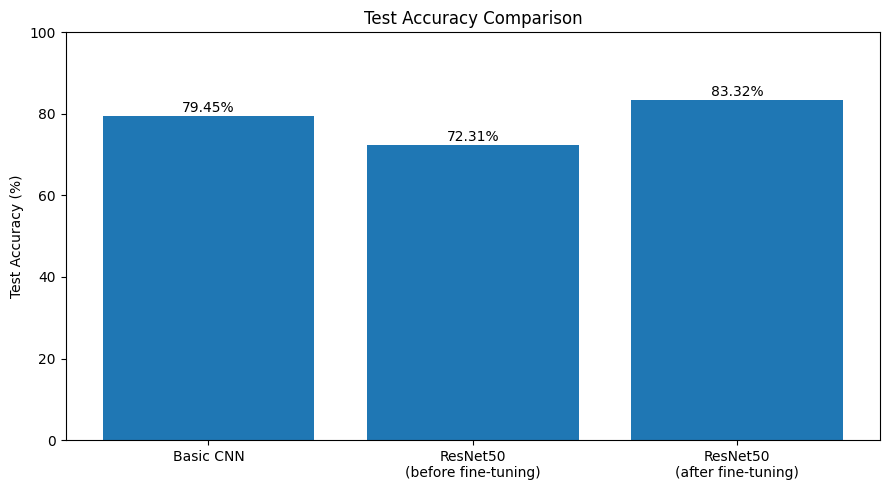

In [ ]:
import matplotlib.pyplot as plt

models = [
    "Basic CNN",
    "ResNet50\n(before fine-tuning)",
    "ResNet50\n(after fine-tuning)"
]

accuracies = [79.45, 72.31, 83.32]

plt.figure(figsize=(9, 5))
bars = plt.bar(models, accuracies)

plt.title("Test Accuracy Comparison")
plt.ylabel("Test Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    "/content/resnet50_accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### **EfficientB0**

In [ ]:
import torch
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights

# Load pretrained EfficientNet-B0
model_eff = efficientnet_b0(
    weights=EfficientNet_B0_Weights.DEFAULT
)

# Freeze pretrained layers
for param in model_eff.parameters():
    param.requires_grad = False

# Replace the final classifier for 2 classes
in_features = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(in_features, 2)

# Move model to GPU
model_eff = model_eff.to(device)

# Configure loss and optimizer
criterion_eff = nn.CrossEntropyLoss()
optimizer_eff = torch.optim.Adam(
    model_eff.classifier[1].parameters(),
    lr=0.001
)

print("EfficientNet-B0 initialized successfully.")
print("Device:", device)
print("Class mapping:", train_data.class_to_idx)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 83.7MB/s]


EfficientNet-B0 initialized successfully.
Device: cuda
Class mapping: {'Fake': 0, 'Real': 1}


In [ ]:
from tqdm.auto import tqdm
import torch

num_epochs_eff = 3

for epoch in range(num_epochs_eff):

    # Training
    model_eff.train()
    train_running_loss = 0.0

    for images, labels in tqdm(
        train_loader,
        desc=f"EfficientNet Epoch {epoch + 1} Training"
    ):
        images = images.to(device)
        labels = labels.to(device)

        optimizer_eff.zero_grad()

        outputs = model_eff(images)
        loss = criterion_eff(outputs, labels)

        loss.backward()
        optimizer_eff.step()

        train_running_loss += loss.item() * images.size(0)

    train_loss = train_running_loss / len(train_loader.dataset)

    # Validation
    model_eff.eval()
    val_running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in tqdm(
            val_loader,
            desc=f"EfficientNet Epoch {epoch + 1} Validation"
        ):
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_eff(images)
            loss = criterion_eff(outputs, labels)

            val_running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)
            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = val_running_loss / len(val_loader.dataset)
    val_accuracy = correct / total

    print(f"\nEfficientNet-B0 Epoch [{epoch + 1}/{num_epochs_eff}]")
    print(f"Train Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")

EfficientNet Epoch 1 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

EfficientNet Epoch 1 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


EfficientNet-B0 Epoch [1/3]
Train Loss: 0.4108
Validation Loss: 0.4136
Validation Accuracy: 80.83%


EfficientNet Epoch 2 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

EfficientNet Epoch 2 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


EfficientNet-B0 Epoch [2/3]
Train Loss: 0.4031
Validation Loss: 0.4195
Validation Accuracy: 80.48%


EfficientNet Epoch 3 Training:   0%|          | 0/4376 [00:00<?, ?it/s]

EfficientNet Epoch 3 Validation:   0%|          | 0/1233 [00:00<?, ?it/s]


EfficientNet-B0 Epoch [3/3]
Train Loss: 0.4034
Validation Loss: 0.4170
Validation Accuracy: 80.80%


In [ ]:
import torch
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

model_eff.eval()

eff_labels = []
eff_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_eff(images)
        predictions = outputs.argmax(dim=1)

        eff_labels.extend(labels.numpy())
        eff_predictions.extend(predictions.cpu().numpy())

eff_accuracy = accuracy_score(eff_labels, eff_predictions)

print(f"EfficientNet-B0 Test Accuracy: {eff_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    eff_labels,
    eff_predictions,
    target_names=["Fake", "Real"],
    digits=4
))

print("\nConfusion Matrix:")
print(confusion_matrix(eff_labels, eff_predictions))


EfficientNet-B0 Test Accuracy: 69.65%

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6604    0.8179    0.7308      5492
        Real     0.7563    0.5732    0.6522      5413

    accuracy                         0.6965     10905
   macro avg     0.7083    0.6956    0.6915     10905
weighted avg     0.7080    0.6965    0.6917     10905


Confusion Matrix:
[[4492 1000]
 [2310 3103]]


In [ ]:
import torch
import json
import shutil
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix
from google.colab import files

# Create results folder
results_dir = Path("/content/efficientnet_b0_results")
results_dir.mkdir(parents=True, exist_ok=True)

# Save model weights
torch.save(
    model_eff.state_dict(),
    results_dir / "efficientnet_b0.pth"
)

# Generate classification metrics
report = classification_report(
    eff_labels,
    eff_predictions,
    target_names=["Fake", "Real"],
    output_dict=True,
    zero_division=0
)

results = {
    "model": "EfficientNet-B0",
    "test_accuracy": float(eff_accuracy),
    "classification_report": report,
    "confusion_matrix": confusion_matrix(
        eff_labels, eff_predictions
    ).tolist()
}

with open(results_dir / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=4)

# Create ZIP and download
zip_path = shutil.make_archive(
    "/content/efficientnet_b0_results",
    "zip",
    str(results_dir)
)

print(f"EfficientNet-B0 Test Accuracy: {eff_accuracy * 100:.2f}%")
files.download(zip_path)

EfficientNet-B0 Test Accuracy: 69.65%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>